# Regresión logística CLV: oportunidades ganadas y perdidas

Este notebook trabaja localmente con Datos_CLV_2026_Tec_v2.xlsx. Solo muestra resultados agregados, nunca registros individuales.

Objetivo: predecir si una oportunidad cerrada terminó perdida (1) o ganada (0), aplicando reponderación de clases.


## 1. Librerías y configuración


In [1]:
import pandas as pd
import numpy as np
import unicodedata
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score

ARCHIVO = Path("Datos_CLV_2026_Tec_v2.xlsx")
SEMILLA = 42

def normalizar_texto(valor):
    if pd.isna(valor):
        return None
    texto = str(valor).strip().lower()
    return "".join(
        caracter for caracter in unicodedata.normalize("NFD", texto)
        if unicodedata.category(caracter) != "Mn"
    )


## 2. Carga mínima y unión de bases

La respuesta proviene de Ventas_Negadas_CRM. Las predictoras provienen de Negocios_CRM. Se unen por id_negocio y solo se leen las columnas requeridas.


In [2]:
negadas = pd.read_excel(
    ARCHIVO,
    sheet_name="Ventas_Negadas_CRM",
    usecols=["id_negocio", "nombre_etapa"]
)

negocios = pd.read_excel(
    ARCHIVO,
    sheet_name="Negocios_CRM",
    usecols=[
        "id_negocio", "tipo_negocio", "oportunidad_ruta",
        "nombre_pipeline", "nombre_zona", "estado"
    ]
)

df = negadas.merge(negocios, on="id_negocio", how="inner")
print(f"Negocios unidos: {len(df):,}")


Negocios unidos: 5,268


## 3. Variable objetivo y nulos

Se conservan solo resultados definitivos. Las etapas abiertas no tienen un desenlace conocido y se excluyen. Para las tres variables originales, los nulos y categorías fuera de catálogo se excluyen. En zona y estado, SIN_DATO se mantiene como categoría.


In [3]:
df["etapa_normalizada"] = df["nombre_etapa"].apply(normalizar_texto)
mapa_resultado = {
    "cierre perdido": 1, "perdido": 1,
    "cierre ganado": 0, "ganado": 0
}
df["resultado_perdido"] = df["etapa_normalizada"].map(mapa_resultado)
df = df.dropna(subset=["resultado_perdido"]).copy()
df["resultado_perdido"] = df["resultado_perdido"].astype(int)

columnas_revision = [
    "tipo_negocio", "oportunidad_ruta", "nombre_pipeline",
    "nombre_zona", "estado"
]
resumen_nulos = pd.DataFrame({
    "nulos": df[columnas_revision].isna().sum(),
    "porcentaje_nulos": (df[columnas_revision].isna().mean() * 100).round(2)
})
display(resumen_nulos)

df["tipo_norm"] = df["tipo_negocio"].apply(normalizar_texto)
df["ruta_norm"] = df["oportunidad_ruta"].apply(normalizar_texto)
df["pipeline_norm"] = df["nombre_pipeline"].apply(normalizar_texto)

tipos_validos = {"cliente existente", "cliente nuevo"}
rutas_validas = {"si", "no"}
pipelines_validos = {
    "pipeline de ventas", "ventas - main",
    "mapeo en ruta", "educacion continua"
}

filas_antes = len(df)
df = df[
    df["tipo_norm"].isin(tipos_validos)
    & df["ruta_norm"].isin(rutas_validas)
    & df["pipeline_norm"].isin(pipelines_validos)
].copy()
print(f"Filas excluidas por nulos o categorías fuera de catálogo: {filas_antes - len(df):,}")
print(f"Casos finales para modelar: {len(df):,}")


,nulos,porcentaje_nulos
tipo_negocio,453,8.99
oportunidad_ruta,0,0.00
nombre_pipeline,0,0.00
nombre_zona,1094,21.71
estado,132,2.62


Filas excluidas por nulos o categorías fuera de catálogo: 454
Casos finales para modelar: 4,584


## 4. Outliers y dicotomización

Estas variables son categóricas. Aquí los outliers son categorías fuera del catálogo permitido, no valores IQR. Después de la transformación, una variable binaria solo puede tomar 0 o 1, por lo que no tiene outliers numéricos.


In [4]:
catalogos = {
    "tipo_negocio": tipos_validos,
    "oportunidad_ruta": rutas_validas,
    "nombre_pipeline": pipelines_validos
}

for columna, categorias_validas in catalogos.items():
    valores_fuera_catalogo = (
        ~df[columna].apply(normalizar_texto).isin(categorias_validas)
    ).sum()
    print(f"{columna}: {valores_fuera_catalogo} valores fuera de catálogo tras la limpieza.")

df["cliente_nuevo"] = (df["tipo_norm"] == "cliente nuevo").astype(int)
df["ruta_si"] = (df["ruta_norm"] == "si").astype(int)
df["pipeline_ventas_main"] = (
    df["pipeline_norm"] == "ventas - main"
).astype(int)

display(
    df[["cliente_nuevo", "ruta_si", "pipeline_ventas_main"]]
    .agg(["min", "max", "sum"])
)


tipo_negocio: 0 valores fuera de catálogo tras la limpieza.
oportunidad_ruta: 0 valores fuera de catálogo tras la limpieza.
nombre_pipeline: 0 valores fuera de catálogo tras la limpieza.


,cliente_nuevo,ruta_si,pipeline_ventas_main
min,0,0,0
max,1,1,1
sum,850,21,393


## 5. Modelo principal: tres variables y reponderación

class_weight="balanced" repondera las clases durante el entrenamiento. Da mayor importancia a pérdidas, que son la clase minoritaria. No crea registros sintéticos.


In [5]:
variables_3 = [
    "cliente_nuevo",
    "ruta_si",
    "pipeline_ventas_main"
]
X = df[variables_3]
y = df["resultado_perdido"]

print("Distribución del resultado:")
display(y.value_counts().rename(index={0: "Ganado", 1: "Perdido"}).to_frame("casos"))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEMILLA, stratify=y
)

modelo_3 = LogisticRegression(
    max_iter=1000, class_weight="balanced", random_state=SEMILLA
)
modelo_3.fit(X_train, y_train)
pred_3 = modelo_3.predict(X_test)

matriz_3 = confusion_matrix(y_test, pred_3)
metricas_3 = pd.DataFrame({
    "exactitud": [accuracy_score(y_test, pred_3)],
    "precision_perdido": [precision_score(y_test, pred_3, zero_division=0)],
    "sensibilidad_perdido": [recall_score(y_test, pred_3, zero_division=0)]
}).round(3)

display(metricas_3)
display(pd.DataFrame(
    matriz_3,
    index=["Real: Ganado", "Real: Perdido"],
    columns=["Predicho: Ganado", "Predicho: Perdido"]
))

display(pd.DataFrame({
    "variable": variables_3,
    "coeficiente": modelo_3.coef_[0].round(3),
    "odds_ratio": np.exp(modelo_3.coef_[0]).round(3)
}))


Distribución del resultado:


,casos
resultado_perdido,
Ganado,3875
Perdido,709


,exactitud,precision_perdido,sensibilidad_perdido
0,0.733,0.293,0.514


,Predicho: Ganado,Predicho: Perdido
Real: Ganado,599,176
Real: Perdido,69,73


,variable,coeficiente,odds_ratio
0,cliente_nuevo,1.268,3.553
1,ruta_si,-1.187,0.305
2,pipeline_ventas_main,0.455,1.575


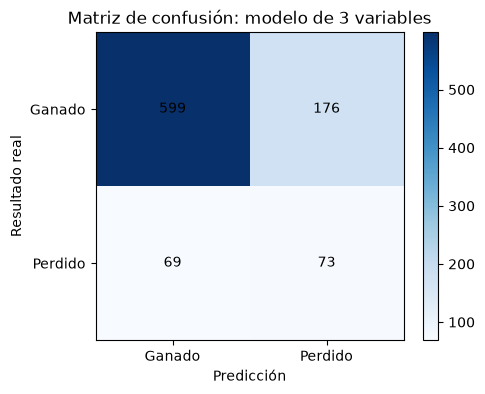

In [6]:
fig, ax = plt.subplots(figsize=(5, 4))
imagen = ax.imshow(matriz_3, cmap="Blues")
ax.set_xticks([0, 1], labels=["Ganado", "Perdido"])
ax.set_yticks([0, 1], labels=["Ganado", "Perdido"])
ax.set_xlabel("Predicción")
ax.set_ylabel("Resultado real")
ax.set_title("Matriz de confusión: modelo de 3 variables")

for fila in range(2):
    for columna in range(2):
        ax.text(columna, fila, matriz_3[fila, columna],
                ha="center", va="center")

fig.colorbar(imagen, ax=ax)
plt.show()


## 6. Construcción de 15 variables dicotómicas

Las primeras cinco provienen de cliente, ruta y pipeline. Las siguientes cinco corresponden a las zonas más frecuentes, conservando SIN_DATO si aparece. Las últimas cinco corresponden a los estados más frecuentes. La selección usa frecuencia y no el resultado, para evitar sesgo de selección.


In [7]:
df["pipeline_mapeo_ruta"] = (
    df["pipeline_norm"] == "mapeo en ruta"
).astype(int)
df["pipeline_educacion_continua"] = (
    df["pipeline_norm"] == "educacion continua"
).astype(int)

df["zona_limpia"] = df["nombre_zona"].apply(normalizar_texto).fillna("sin_dato")
df["estado_limpio"] = df["estado"].apply(normalizar_texto).fillna("sin_dato")

zonas_top_5 = df["zona_limpia"].value_counts().head(5).index.tolist()
estados_top_5 = df["estado_limpio"].value_counts().head(5).index.tolist()

for posicion, categoria in enumerate(zonas_top_5, start=1):
    df[f"zona_top_{posicion}"] = (df["zona_limpia"] == categoria).astype(int)

for posicion, categoria in enumerate(estados_top_5, start=1):
    df[f"estado_top_{posicion}"] = (df["estado_limpio"] == categoria).astype(int)

variables_15 = [
    "cliente_nuevo", "ruta_si",
    "pipeline_ventas_main", "pipeline_mapeo_ruta",
    "pipeline_educacion_continua",
    *[f"zona_top_{i}" for i in range(1, 6)],
    *[f"estado_top_{i}" for i in range(1, 6)]
]

diccionario_15 = pd.DataFrame({
    "variable_binaria": variables_15,
    "categoria_1": [
        "cliente nuevo", "si", "ventas - main", "mapeo en ruta",
        "educacion continua", *zonas_top_5, *estados_top_5
    ],
    "categoria_0": "cualquier otra categoría"
})
display(diccionario_15)
print(f"Total de variables dicotómicas: {len(variables_15)}")


,variable_binaria,categoria_1,categoria_0
0,cliente_nuevo,cliente nuevo,cualquier otra categoría
1,ruta_si,si,cualquier otra categoría
2,pipeline_ventas_main,ventas - main,cualquier otra categoría
3,pipeline_mapeo_ruta,mapeo en ruta,cualquier otra categoría
4,pipeline_educacion_continua,educacion continua,cualquier otra categoría
5,zona_top_1,zona metropolitana,cualquier otra categoría
6,zona_top_2,zona sur este golfo de mexico,cualquier otra categoría
7,zona_top_3,sin_dato,cualquier otra categoría
8,zona_top_4,zona bajio,cualquier otra categoría
9,zona_top_5,zona occidente pacifico,cualquier otra categoría


Total de variables dicotómicas: 15


## 7. Quince análisis de clasificación

Se ajusta una regresión logística independiente para cada variable dicotómica. Cada modelo usa la misma partición entrenamiento/prueba y reponderación de clases. La tabla final muestra las métricas pedidas; después se presentan las 15 matrices de confusión.


In [8]:
X_train_base, X_test_base, y_train_15, y_test_15 = train_test_split(
    df[variables_15],
    y,
    test_size=0.20,
    random_state=SEMILLA,
    stratify=y
)

resultados_15 = []
matrices_15 = {}

for variable in variables_15:
    modelo = LogisticRegression(
        max_iter=1000, class_weight="balanced", random_state=SEMILLA
    )
    modelo.fit(X_train_base[[variable]], y_train_15)
    prediccion = modelo.predict(X_test_base[[variable]])
    matriz = confusion_matrix(y_test_15, prediccion)

    matrices_15[variable] = matriz
    resultados_15.append({
        "variable": variable,
        "exactitud": accuracy_score(y_test_15, prediccion),
        "precision": precision_score(y_test_15, prediccion, zero_division=0),
        "sensibilidad": recall_score(y_test_15, prediccion, zero_division=0),
        "VP": matriz[1, 1],
        "FN": matriz[1, 0],
        "FP": matriz[0, 1],
        "VN": matriz[0, 0]
    })

tabla_metricas_15 = (
    pd.DataFrame(resultados_15)
    .sort_values("sensibilidad", ascending=False)
    .reset_index(drop=True)
)
display(tabla_metricas_15.round(3))


,variable,exactitud,precision,sensibilidad,VP,FN,FP,VN
0,ruta_si,0.159,0.154,0.986,140,2,769,6
1,estado_top_2,0.289,0.176,0.972,138,4,648,127
2,estado_top_1,0.339,0.183,0.944,134,8,598,177
3,zona_top_1,0.424,0.200,0.908,129,13,515,260
4,zona_top_3,0.326,0.159,0.782,111,31,587,188
5,cliente_nuevo,0.771,0.317,0.415,59,83,127,648
6,zona_top_2,0.707,0.207,0.317,45,97,172,603
7,zona_top_5,0.828,0.386,0.190,27,115,43,732
8,estado_top_3,0.764,0.202,0.176,25,117,99,676
9,zona_top_4,0.766,0.183,0.148,21,121,94,681


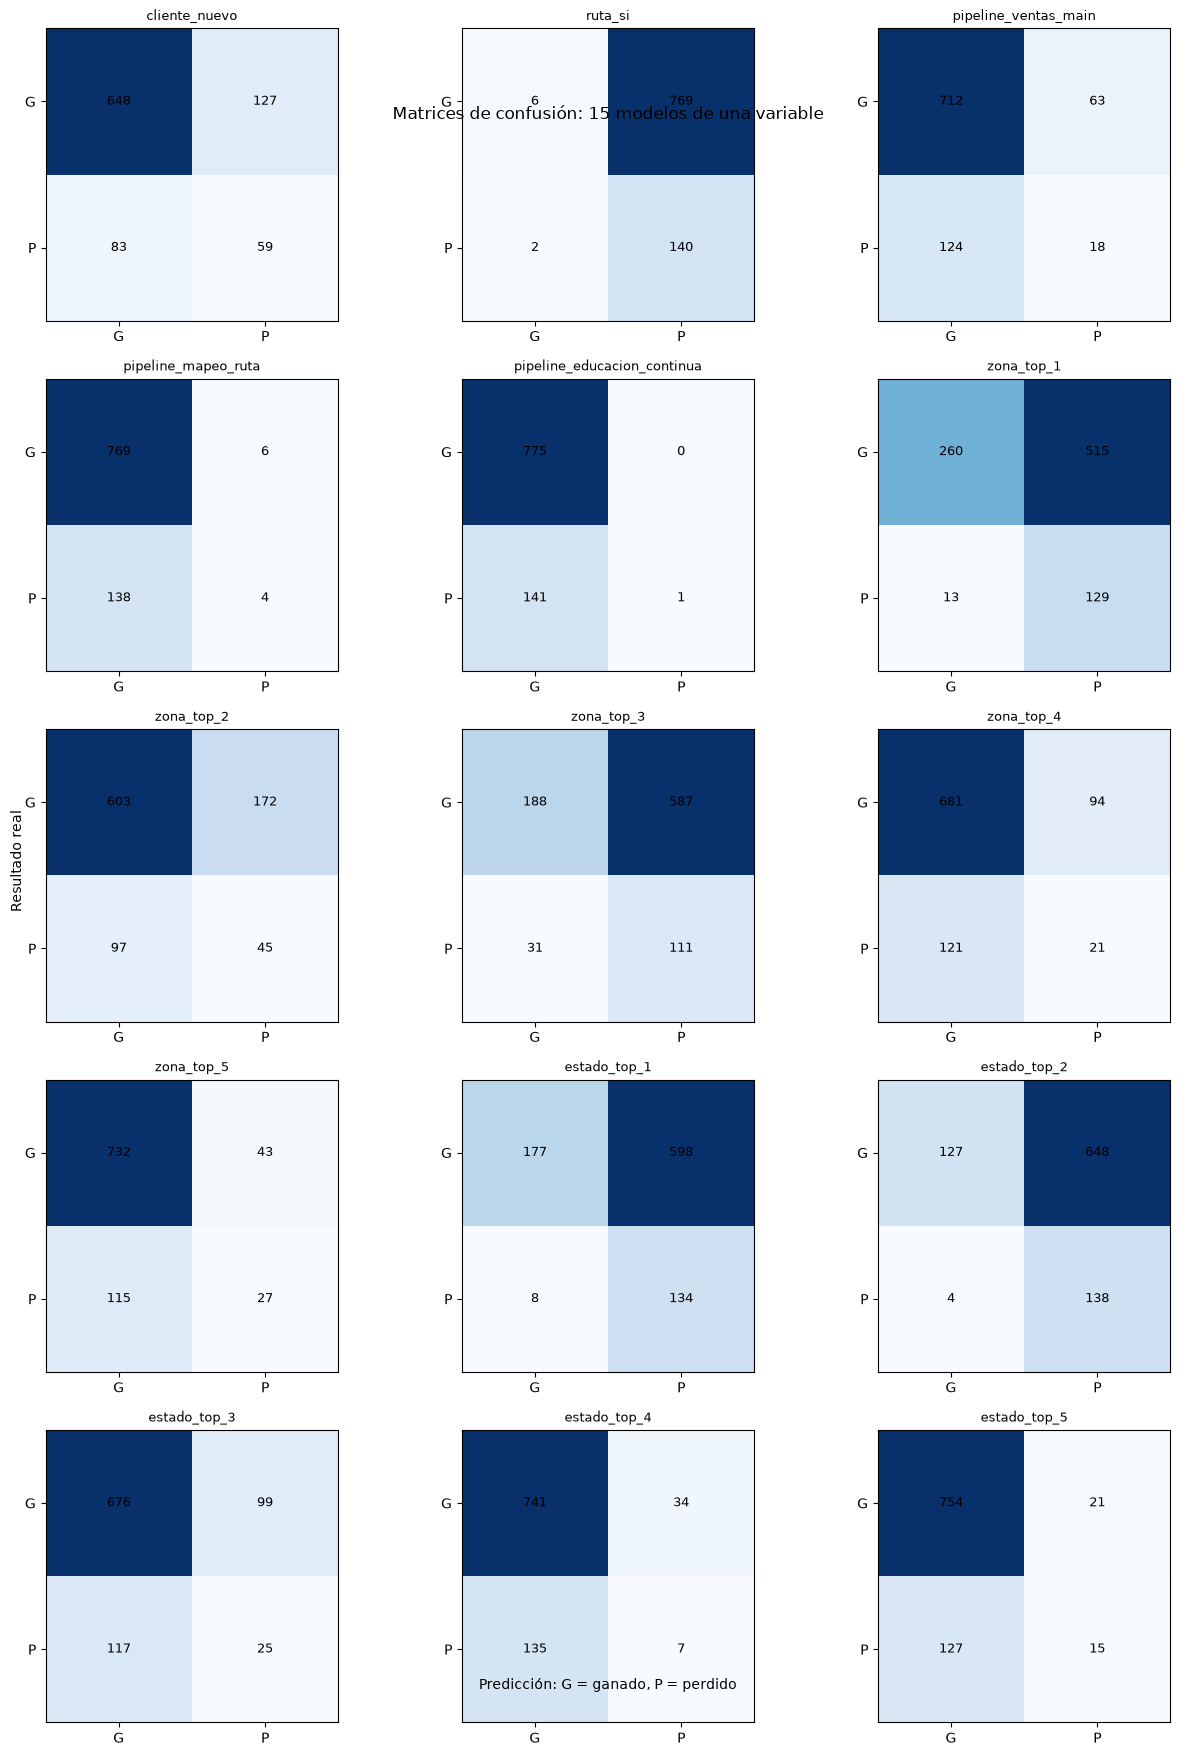

In [9]:
fig, ejes = plt.subplots(5, 3, figsize=(13, 18))
ejes = ejes.ravel()

for eje, variable in zip(ejes, variables_15):
    matriz = matrices_15[variable]
    eje.imshow(matriz, cmap="Blues")
    eje.set_title(variable, fontsize=9)
    eje.set_xticks([0, 1], labels=["G", "P"])
    eje.set_yticks([0, 1], labels=["G", "P"])
    for fila in range(2):
        for columna in range(2):
            eje.text(columna, fila, matriz[fila, columna],
                     ha="center", va="center", fontsize=9)

fig.suptitle("Matrices de confusión: 15 modelos de una variable", y=0.92)
fig.text(0.5, 0.04, "Predicción: G = ganado, P = perdido", ha="center")
fig.text(0.04, 0.5, "Resultado real", va="center", rotation="vertical")
plt.tight_layout()
plt.show()


## 8. Interpretación y límites

- La exactitud es la proporción total de aciertos.
- La precisión indica qué proporción de predicciones de pérdida fue realmente pérdida.
- La sensibilidad indica qué proporción de pérdidas reales fue detectada.
- Un modelo de una sola variable sirve para comparar poder predictivo individual. El modelo de tres variables estima su efecto conjunto.
- No se usan como predictoras nombre_etapa, estatus, motivo_cierre_perdido, fecha_cierre, ultima_modificacion ni valor_negocio, porque pueden revelar el resultado final.
- Para una entrega final, documenta los valores fuera de catálogo excluidos y conserva la semilla 42 para reproducibilidad.
